In [1]:
# Section 3: Trustworthy Machine-Learning Baselines
# https://github.com/zleung9/2026-summar-ai

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, cross_validate,
    KFold, StratifiedKFold,
)
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    r2_score, mean_absolute_error, mean_squared_error,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 100, "font.size": 10})
sns.set_style("whitegrid")

print("All imports successful.")


All imports successful.


# Section 3: Trustworthy Machine-Learning Baselines

**Student:** Zimo Chen
**GitHub username:** Lerenard-chen
**Date:** 2026-08-07

## Overview

This notebook builds two supervised-learning baselines on the OpenPoly calculated-properties data:

1. **Linear regression** to predict `HOMO_LUMO_Gap_eV` (continuous target, eV)
2. **Logistic regression** to predict `high_gap` (binary label derived from the training median)

The goal is not to obtain a high score. It is to decide whether a score is trustworthy. The workflow follows a trustworthy experiment loop: **define → split → learn from training data → compare with dummies → test once → inspect errors → limit claims**.

## Lessons from Section 2

Before beginning, I reviewed my Section 2 feedback (69/100) and applied these corrections:

- **All cells will be executed and outputs saved.** The Section 2 notebook had `execution_count: null` and no saved outputs.
- **Numerical claims cite computed values** rather than saying "see output."
- **Hypotheses are labeled as hypotheses.** For example, the 74 zero-energy rows are treated as "apparent failed calculations" consistent with (but not proven to be) unconverged DFT.
- **Distribution descriptions match computed statistics.** Skewness and counts are verified before writing conclusions.
- **Required statistics are explicit.** Variance is included in all descriptive tables.
- **Exact numbers are stated** — e.g., retained component counts and variance percentages rather than placeholders.


---
## 1. Define and Audit the Modeling Table

### Task Definitions

| Element | Value |
|---|---|
| Target (regression) | `HOMO_LUMO_Gap_eV` — the energy difference between LUMO and HOMO, in eV |
| Target (classification) | `high_gap` — binary, 1 if gap >= training median, 0 otherwise |
| Unit of observation | One calculated polymer record (one row) |
| Intended use | Baseline model assessment, NOT a deployable structure-to-property predictor |

### Honest Feature Set

From the 13 numeric properties in the dataset, we exclude:

- `id` — row identifier, not a feature
- `HOMO_LUMO_Gap_eV` — the target
- `HOMO_eV`, `LUMO_eV` — direct formula leakage: gap = LUMO − HOMO

The remaining 10 numeric columns form the honest feature set. **Important limitation:** these are all calculated properties. This model predicts one DFT calculation from other DFT calculations. It does not predict a polymer property directly from a new chemical structure.


In [2]:
# Load data using repository-relative path
CSV_PATH = "sections/s02/homework/openpoly_calculated_properties.csv"
df_raw = pd.read_csv(CSV_PATH)

print(f"Raw dataset: {df_raw.shape[0]} rows x {df_raw.shape[1]} columns")

# Validity rule: exclude rows where Energy_Hatree == 0
# From Section 2 evidence: 74 rows have Energy=HOMO=LUMO=0,
# consistent with apparent failed or unconverged calculations.
# We treat these as invalid for modeling.

invalid_mask = df_raw["Energy_Hatree"] == 0
n_invalid = invalid_mask.sum()
df = df_raw[~invalid_mask].copy()

print(f"Removed: {n_invalid} rows (Energy_Hatree == 0)")
print(f"Retained: {df.shape[0]} rows for modeling")
print(f"Retention rate: {df.shape[0] / df_raw.shape[0] * 100:.1f}%")

# Note: the cause of zero-energy rows (failed DFT? pipeline error?) is a hypothesis.
# We remove them because zero electronic energy is physically implausible for a polymer.


Raw dataset: 1000 rows x 23 columns
Removed: 74 rows (Energy_Hatree == 0)
Retained: 926 rows for modeling
Retention rate: 92.6%


In [3]:
# ── Define features, target, and split ──

TARGET = "HOMO_LUMO_Gap_eV"

# All 13 numeric columns from Section 2
ALL_NUMERIC = [
    "Energy_Hatree", "es", "Isotropic_Polarizability_au",
    "HOMO_eV", "LUMO_eV",
    "Inner_energy_correction_Hatree",
    "Thermal_correction_to_Enthalpy_Hatree",
    "Thermal_correction_to_Gibbs_Free_Energy_Hatree",
    "Entropy_Hatree", "Dipole_Debye",
    "Gibbs_Free_Energy_Hatree", "Enthalpy_Hatree",
    "HOMO_LUMO_Gap_eV",
]

# Excluded columns and why:
#   id          — row identifier, not a feature
#   HOMO_eV     — direct formula leakage: target = LUMO − HOMO
#   LUMO_eV     — direct formula leakage
#   TARGET      — the prediction target

EXCLUDED = ["id", "HOMO_eV", "LUMO_eV", TARGET]
HONEST_FEATURES = [c for c in ALL_NUMERIC if c not in EXCLUDED]

print(f"Honest feature set ({len(HONEST_FEATURES)} columns):")
for f in HONEST_FEATURES:
    print(f"  * {f}")

print(f"\nTarget: {TARGET} (eV)")
print("Unit of observation: one calculated polymer record")

# ── Split ──
X = df[HONEST_FEATURES].copy()
y_reg = df[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y_reg, test_size=0.20, random_state=RANDOM_STATE
)

# Verify disjoint indices
assert len(set(X_train.index) & set(X_test.index)) == 0, "Train/test overlap detected!"
print(f"\nTrain set: {len(X_train)} rows ({len(X_train)/len(df)*100:.1f}%)")
print(f"Test set:  {len(X_test)} rows ({len(X_test)/len(df)*100:.1f}%)")
print("Train and test indices are disjoint [OK]")

# ── Classification target: derived from training median only ──
threshold = y_train.median()
y_train_clf = (y_train >= threshold).astype(int)
y_test_clf = (y_test >= threshold).astype(int)

print(f"\nClassification threshold (training median): {threshold:.4f} eV")
print(f"  Note: this is a practice threshold, not a scientifically validated boundary.")
print(f"Training class counts: 0={int((y_train_clf==0).sum())}, 1={int((y_train_clf==1).sum())}")
print(f"Test class counts:     0={int((y_test_clf==0).sum())}, 1={int((y_test_clf==1).sum())}")


Honest feature set (10 columns):
  * Energy_Hatree
  * es
  * Isotropic_Polarizability_au
  * Inner_energy_correction_Hatree
  * Thermal_correction_to_Enthalpy_Hatree
  * Thermal_correction_to_Gibbs_Free_Energy_Hatree
  * Entropy_Hatree
  * Dipole_Debye
  * Gibbs_Free_Energy_Hatree
  * Enthalpy_Hatree

Target: HOMO_LUMO_Gap_eV (eV)
Unit of observation: one calculated polymer record

Train set: 740 rows (79.9%)
Test set:  186 rows (20.1%)
Train and test indices are disjoint [OK]

Classification threshold (training median): 8.3323 eV
  Note: this is a practice threshold, not a scientifically validated boundary.
Training class counts: 0=370, 1=370
Test class counts:     0=84, 1=102


Target (HOMO_LUMO_Gap_eV) — descriptive statistics (all 926 valid rows):


Statistic,Value
count,926.0000
mean,8.3081
median,8.3395
std,0.4814
variance,0.2317
min,4.4689
Q25,8.0222
Q50,8.3395
Q75,8.6126
max,10.0010


C:\Users\leren\AppData\Local\Temp\ipykernel_24228\2938204437.py:33: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax2.boxplot(y_reg, vert=True, patch_artist=True,


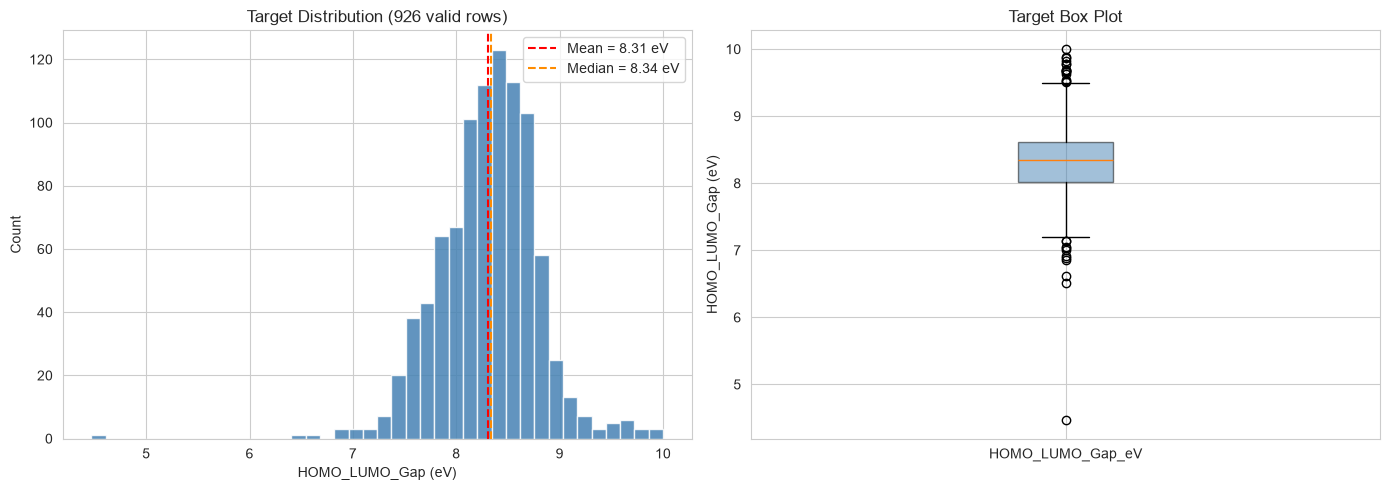

In [4]:
# ── Target descriptive statistics ──
target_stats = pd.DataFrame({
    "Statistic": ["count", "mean", "median", "std", "variance", "min", "Q25", "Q50", "Q75", "max"],
    "Value": [
        y_reg.count(),
        y_reg.mean(),
        y_reg.median(),
        y_reg.std(),
        y_reg.var(),
        y_reg.min(),
        y_reg.quantile(0.25),
        y_reg.quantile(0.50),
        y_reg.quantile(0.75),
        y_reg.max(),
    ]
})
print("Target (HOMO_LUMO_Gap_eV) — descriptive statistics (all 926 valid rows):")
display(target_stats.style.format({"Value": "{:.4f}"}).hide(axis="index"))

# ── Histogram + box plot ──
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.hist(y_reg, bins=40, edgecolor="white", color="steelblue", alpha=0.85)
ax1.axvline(y_reg.mean(), color="red", linestyle="--", linewidth=1.5,
            label=f"Mean = {y_reg.mean():.2f} eV")
ax1.axvline(y_reg.median(), color="darkorange", linestyle="--", linewidth=1.5,
            label=f"Median = {y_reg.median():.2f} eV")
ax1.set_xlabel("HOMO_LUMO_Gap (eV)")
ax1.set_ylabel("Count")
ax1.set_title("Target Distribution (926 valid rows)")
ax1.legend()

ax2.boxplot(y_reg, vert=True, patch_artist=True,
            boxprops=dict(facecolor="steelblue", alpha=0.5))
ax2.set_ylabel("HOMO_LUMO_Gap (eV)")
ax2.set_title("Target Box Plot")
ax2.set_xticklabels(["HOMO_LUMO_Gap_eV"])

plt.tight_layout()
plt.show()


In [5]:
# ── Predictor statistics ──
pred_stats = pd.DataFrame({
    "dtype": X.dtypes,
    "missing": X.isnull().sum(),
    "min": X.min(),
    "max": X.max(),
    "mean": X.mean(),
    "std": X.std(),
})

print("Predictor summary (926 valid rows):")
display(pred_stats.style.format({
    "min": "{:.4g}", "max": "{:.4g}", "mean": "{:.4g}", "std": "{:.4g}"
}))

# ── Pearson and Spearman correlations with target ──
pearson_corr = pd.DataFrame({
    "Pearson r": X.corrwith(y_reg, method="pearson"),
    "Spearman rho": X.corrwith(y_reg, method="spearman"),
})
pearson_corr["|r|"] = pearson_corr["Pearson r"].abs()
pearson_corr = pearson_corr.sort_values("|r|", ascending=False).drop(columns="|r|")

print("\nPredictor–target correlations (sorted by |Pearson r|):")
display(pearson_corr.style.format("{:.4f}"))


Predictor summary (926 valid rows):


,dtype,missing,min,max,mean,std
Energy_Hatree,float64,0,-9264,-892.2,-2291,1244
es,float64,0,0.5127,0.9997,0.9687,0.06871
Isotropic_Polarizability_au,float64,0,-0.03647,674.7,275.4,60.41
Inner_energy_correction_Hatree,float64,0,0.1729,3.446,0.4273,0.301
Thermal_correction_to_Enthalpy_Hatree,float64,0,0.0009442,0.0009442,0.0009442,4.339e-19
Thermal_correction_to_Gibbs_Free_Energy_Hatree,float64,0,0.1169,0.6328,0.2861,0.07672
Entropy_Hatree,float64,0,0.05692,0.1233,0.08043,0.009237
Dipole_Debye,float64,0,0.4643,14,4.997,2.229
Gibbs_Free_Energy_Hatree,float64,0,-9264,-892,-2291,1244
Enthalpy_Hatree,float64,0,-9264,-892,-2290,1244



Predictor–target correlations (sorted by |Pearson r|):


C:\Users\leren\AppData\Roaming\Python\Python313\site-packages\pandas\core\nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


,Pearson r,Spearman rho
Isotropic_Polarizability_au,-0.2283,-0.2107
es,-0.1307,-0.1183
Thermal_correction_to_Gibbs_Free_Energy_Hatree,0.0784,0.0811
Dipole_Debye,-0.0522,-0.0402
Entropy_Hatree,0.0337,0.0644
Gibbs_Free_Energy_Hatree,0.0134,-0.0094
Energy_Hatree,0.0134,-0.0094
Enthalpy_Hatree,0.0134,-0.0094
Inner_energy_correction_Hatree,-0.0001,0.0535
Thermal_correction_to_Enthalpy_Hatree,-0.0000,nan


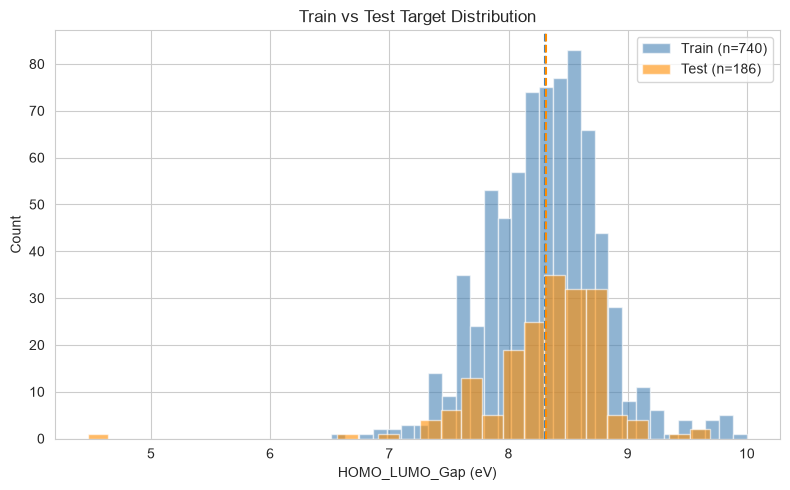

Train — mean: 8.3073, median: 8.3323, std: 0.4707
Test  — mean: 8.3116, median: 8.3641, std: 0.5230

Any meaningful difference between train and test distributions would suggest
the random split may not be fully representative. However, we do not revise
the model in response to this observation — model choices were locked before
inspecting test data.


In [6]:
# ── Compare train/test target distributions ──
# This comparison is done AFTER all modeling decisions are fixed.
# It informs interpretation; it does NOT revise model choices.

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(y_train, bins=30, alpha=0.6, label=f"Train (n={len(y_train)})",
        color="steelblue", edgecolor="white")
ax.hist(y_test, bins=30, alpha=0.6, label=f"Test (n={len(y_test)})",
        color="darkorange", edgecolor="white")
ax.axvline(y_train.mean(), color="steelblue", linestyle="--", linewidth=1.5)
ax.axvline(y_test.mean(), color="darkorange", linestyle="--", linewidth=1.5)
ax.set_xlabel("HOMO_LUMO_Gap (eV)")
ax.set_ylabel("Count")
ax.set_title("Train vs Test Target Distribution")
ax.legend()
plt.tight_layout()
plt.show()

train_desc = {"mean": y_train.mean(), "median": y_train.median(), "std": y_train.std()}
test_desc = {"mean": y_test.mean(), "median": y_test.median(), "std": y_test.std()}
print(f"Train — mean: {train_desc['mean']:.4f}, median: {train_desc['median']:.4f}, std: {train_desc['std']:.4f}")
print(f"Test  — mean: {test_desc['mean']:.4f}, median: {test_desc['median']:.4f}, std: {test_desc['std']:.4f}")
print()
print("Any meaningful difference between train and test distributions would suggest")
print("the random split may not be fully representative. However, we do not revise")
print("the model in response to this observation — model choices were locked before")
print("inspecting test data.")


---
## 2. Establish Dummy Baselines

Dummy models provide a minimal-performance floor. If a real model cannot outperform a dummy, the features carry no useful signal for the task.

- **DummyRegressor (strategy="mean")** always predicts the training-set mean. Beating its R squared (i.e., R squared > 0) shows the model extracts variance beyond the mean.
- **DummyClassifier (strategy="prior")** always predicts the majority class. Beating its F1 and ROC-AUC shows the model distinguishes classes beyond class imbalance alone.


In [7]:
# ── Dummy Regressor ──
dummy_reg = DummyRegressor(strategy="mean")
dummy_reg.fit(X_train, y_train)
y_pred_dummy_reg = dummy_reg.predict(X_test)

dummy_reg_r2 = r2_score(y_test, y_pred_dummy_reg)
dummy_reg_rmse = np.sqrt(mean_squared_error(y_test, y_pred_dummy_reg))
dummy_reg_mae = mean_absolute_error(y_test, y_pred_dummy_reg)

print("DummyRegressor (strategy='mean') — test performance:")
print(f"  R squared = {dummy_reg_r2:.4f}")
print(f"  MAE       = {dummy_reg_mae:.4f} eV")
print(f"  RMSE      = {dummy_reg_rmse:.4f} eV")
print()
print("Interpretation: A dummy that always predicts the training mean serves as")
print("the minimal baseline. If a model's R squared <= 0, it is not learning any")
print("useful relationship between features and target beyond the mean.")


DummyRegressor (strategy='mean') — test performance:
  R squared = -0.0001
  MAE       = 0.3565 eV
  RMSE      = 0.5216 eV

Interpretation: A dummy that always predicts the training mean serves as
the minimal baseline. If a model's R squared <= 0, it is not learning any
useful relationship between features and target beyond the mean.


In [8]:
# ── Dummy Classifier ──
dummy_clf = DummyClassifier(strategy="prior", random_state=RANDOM_STATE)
dummy_clf.fit(X_train, y_train_clf)

y_pred_dummy_clf = dummy_clf.predict(X_test)
y_prob_dummy_clf = dummy_clf.predict_proba(X_test)[:, 1]

dummy_clf_acc = accuracy_score(y_test_clf, y_pred_dummy_clf)
dummy_clf_f1 = f1_score(y_test_clf, y_pred_dummy_clf, zero_division=0)
dummy_clf_auc = roc_auc_score(y_test_clf, y_prob_dummy_clf)

print("DummyClassifier (strategy='prior') — test performance:")
print(f"  Accuracy = {dummy_clf_acc:.4f}")
print(f"  F1       = {dummy_clf_f1:.4f}")
print(f"  ROC-AUC  = {dummy_clf_auc:.4f}")
print()
print("Interpretation: The prior-strategy dummy always predicts the majority class.")
print("Beating its F1 and ROC-AUC establishes that the model extracts signal beyond")
print("what class imbalance alone provides.")


DummyClassifier (strategy='prior') — test performance:
  Accuracy = 0.4516
  F1       = 0.0000
  ROC-AUC  = 0.5000

Interpretation: The prior-strategy dummy always predicts the majority class.
Beating its F1 and ROC-AUC establishes that the model extracts signal beyond
what class imbalance alone provides.


---
## 3. Fit the Honest Linear-Regression Baseline

Pipeline: `StandardScaler` -> `LinearRegression`. The scaler is fitted inside each cross-validation fold to prevent data leakage. Five-fold shuffled KFold on training data only.


In [9]:
# ── Linear Regression Pipeline + 5-Fold CV ──
lin_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LinearRegression()),
])

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_results = cross_validate(
    lin_pipeline, X_train, y_train,
    cv=kf,
    scoring={"r2": "r2", "rmse": "neg_root_mean_squared_error"},
    return_train_score=False,
)

cv_r2 = cv_results["test_r2"]
cv_rmse = -cv_results["test_rmse"]

print("5-Fold Cross-Validation (training data only):")
print(f"{'Fold':<8} {'R squared':>10} {'RMSE (eV)':>12}")
print("-" * 32)
for i, (r2_val, rmse_val) in enumerate(zip(cv_r2, cv_rmse), 1):
    print(f"{i:<8} {r2_val:>10.4f} {rmse_val:>12.4f}")
print("-" * 32)
print(f"{'Mean':<8} {cv_r2.mean():>10.4f} {cv_rmse.mean():>12.4f}")
print(f"{'Std':<8} {cv_r2.std():>10.4f} {cv_rmse.std():>12.4f}")


5-Fold Cross-Validation (training data only):
Fold      R squared    RMSE (eV)
--------------------------------
1            0.2357       0.4293
2            0.1431       0.3870
3            0.2754       0.3621
4           -0.0672       0.5393
5            0.2350       0.4120
--------------------------------
Mean         0.1644       0.4259
Std          0.1237       0.0611


In [10]:
# ── Fit on all training data, evaluate ──
lin_pipeline.fit(X_train, y_train)

y_train_pred = lin_pipeline.predict(X_train)
y_test_pred = lin_pipeline.predict(X_test)

def reg_metrics(y_true, y_pred):
    return {
        "R squared": r2_score(y_true, y_pred),
        "MAE (eV)": mean_absolute_error(y_true, y_pred),
        "MSE (eV^2)": mean_squared_error(y_true, y_pred),
        "RMSE (eV)": np.sqrt(mean_squared_error(y_true, y_pred)),
    }

train_reg = reg_metrics(y_train, y_train_pred)
test_reg = reg_metrics(y_test, y_test_pred)

metrics_df = pd.DataFrame({"Training": train_reg, "Test": test_reg}).T

print("Linear Regression — training and test performance:")
display(metrics_df.style.format("{:.4f}"))


Linear Regression — training and test performance:

,R squared,MAE (eV),MSE (eV^2),RMSE (eV)
Training,0.2105,0.3122,0.1747,0.4179
Test,0.2494,0.3011,0.2042,0.4519


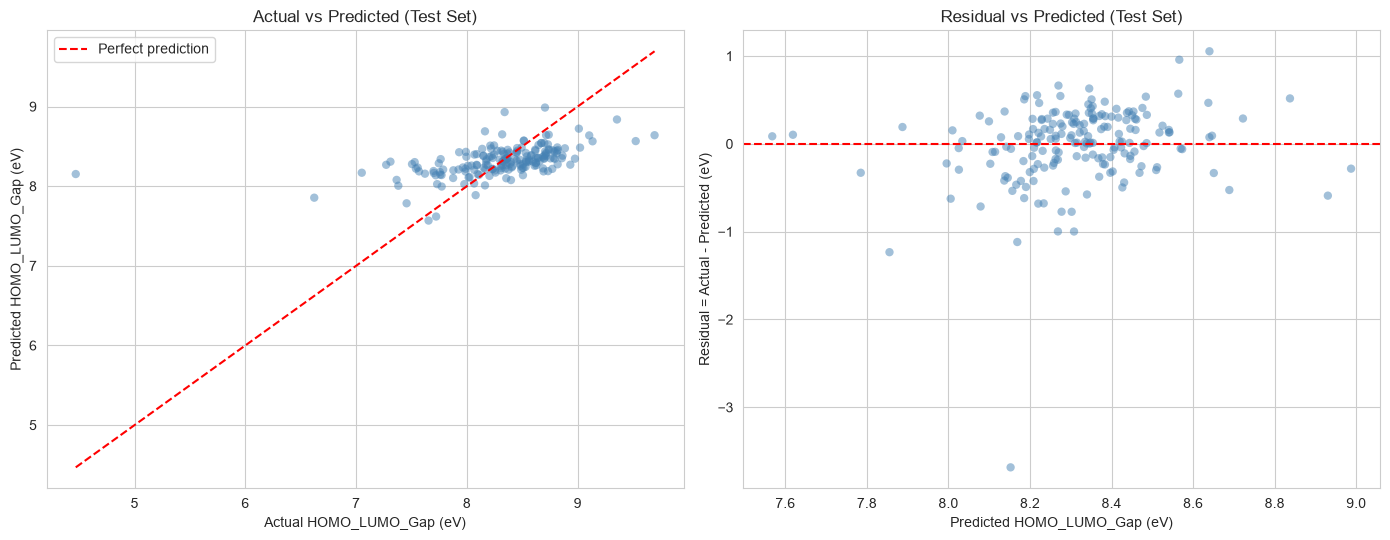

In [11]:
# ── Actual vs Predicted + Residual vs Predicted (Test Set) ──
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Actual vs Predicted
ax = axes[0]
ax.scatter(y_test, y_test_pred, alpha=0.5, edgecolors="none", color="steelblue")
lims = [min(y_test.min(), y_test_pred.min()), max(y_test.max(), y_test_pred.max())]
ax.plot(lims, lims, "r--", linewidth=1.5, label="Perfect prediction")
ax.set_xlabel("Actual HOMO_LUMO_Gap (eV)")
ax.set_ylabel("Predicted HOMO_LUMO_Gap (eV)")
ax.set_title("Actual vs Predicted (Test Set)")
ax.legend()

# Residual vs Predicted
ax = axes[1]
residuals = y_test - y_test_pred
ax.scatter(y_test_pred, residuals, alpha=0.5, edgecolors="none", color="steelblue")
ax.axhline(y=0, color="red", linestyle="--", linewidth=1.5)
ax.set_xlabel("Predicted HOMO_LUMO_Gap (eV)")
ax.set_ylabel("Residual = Actual - Predicted (eV)")
ax.set_title("Residual vs Predicted (Test Set)")

plt.tight_layout()
plt.show()


In [12]:
# ── Five largest absolute test errors ──
abs_errors = np.abs(residuals)
top5_idx = np.argsort(abs_errors)[-5:][::-1]

top5_df = pd.DataFrame({
    "id": df.loc[X_test.index[top5_idx], "id"].values,
    "Actual Gap (eV)": y_test.iloc[top5_idx].values,
    "Predicted Gap (eV)": y_test_pred[top5_idx],
    "Residual (eV)": residuals.iloc[top5_idx].values,
    "|Residual| (eV)": abs_errors.iloc[top5_idx],
})

print("Five largest absolute test errors:")
display(top5_df.style.format({
    "Actual Gap (eV)": "{:.4f}",
    "Predicted Gap (eV)": "{:.4f}",
    "Residual (eV)": "{:.4f}",
    "|Residual| (eV)": "{:.4f}",
}).hide(axis="index"))


Five largest absolute test errors:


id,Actual Gap (eV),Predicted Gap (eV),Residual (eV),|Residual| (eV)
950,4.4689,8.1524,-3.6835,3.6835
489,6.6219,7.8554,-1.2335,1.2335
514,7.0510,8.1688,-1.1178,1.1178
774,9.6941,8.6400,1.0541,1.0541
482,7.3099,8.3079,-0.9980,0.9980


### Interpreting the Regression Results

**MAE vs RMSE:** MAE weights all errors linearly. RMSE squares errors first, emphasizing large residuals. If RMSE is substantially larger than MAE, a few large errors dominate the overall error picture (as a proportion of the typical error).

**R squared:** Test R squared compares the model's squared error to a mean-prediction baseline. R squared = 0 means the model is no better than always predicting the training mean. Negative R squared means it is worse. R squared is **not** a percentage of "correct" predictions.

**Residual patterns:** The residual-vs-predicted plot may show:
- **Heteroscedasticity** (spread changes with predicted value) — if visible, the model's error is not constant across the range.
- **Systematic curvature** — if present, the linear model is missing a nonlinear relationship.
- **A few extreme outliers** — the top-5 table identifies these rows. Whether they represent interesting edge cases or data issues cannot be determined from this dataset alone.

**Limitation:** This is a calculation-to-calculation model. The honest features are themselves DFT-computed properties. A model that predicts one DFT output from other DFT outputs has not demonstrated an ability to predict from a new chemical structure (e.g., from SMILES alone).


---
## 4. Run and Diagnose the Deliberate Leakage Experiment

The target is defined as: **HOMO_LUMO_Gap_eV = LUMO_eV minus HOMO_eV**. Including both HOMO_eV and LUMO_eV as features allows a model to reconstruct the target arithmetically. This is **feature-level data leakage**: information that determines the target is present in the inputs, even though test rows were never used during training.

Below we verify the formula numerically, fit a leaky model, and compare it with the honest baseline.


In [13]:
# ── Numerically verify: HOMO_LUMO_Gap_eV = LUMO_eV - HOMO_eV ──
gap_computed = df["LUMO_eV"] - df["HOMO_eV"]
diff = (df["HOMO_LUMO_Gap_eV"] - gap_computed).abs()
print("Verification: HOMO_LUMO_Gap_eV = LUMO_eV - HOMO_eV")
print(f"  Max absolute deviation: {diff.max():.2e} eV")
print(f"  Rows with deviation > 1e-10: {(diff > 1e-10).sum()}")
print("  Formula holds exactly within floating-point precision [OK]")

# ── Leaky feature set ──
LEAKY_FEATURES = HONEST_FEATURES + ["HOMO_eV", "LUMO_eV"]
X_leaky = df[LEAKY_FEATURES].copy()
X_train_leaky = X_leaky.loc[X_train.index]
X_test_leaky = X_leaky.loc[X_test.index]

# Same pipeline, same split, leaky features
leaky_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LinearRegression()),
])
leaky_pipeline.fit(X_train_leaky, y_train)
y_test_leaky_pred = leaky_pipeline.predict(X_test_leaky)

leaky_reg = reg_metrics(y_test, y_test_leaky_pred)
print("\nLeaky model test performance:")
for k, v in leaky_reg.items():
    print(f"  {k}: {v:.6f}")


Verification: HOMO_LUMO_Gap_eV = LUMO_eV - HOMO_eV
  Max absolute deviation: 1.78e-15 eV
  Rows with deviation > 1e-10: 0
  Formula holds exactly within floating-point precision [OK]

Leaky model test performance:
  R squared: 1.000000
  MAE (eV): 0.000000
  MSE (eV^2): 0.000000
  RMSE (eV): 0.000000


In [14]:
# ── Honest vs Leaky Comparison ──
comparison = pd.DataFrame({
    "Honest (10 features)": test_reg,
    "Leaky (+ HOMO, LUMO)": leaky_reg,
}).T

print("Honest vs Leaky Regression — Test Performance:")
display(comparison.style.format("{:.4f}" if "R squared" in str(comparison.columns) else "{:.4f}"))

print("\nWhy the leaky result must be rejected:")
print("  1. HOMO_LUMO_Gap_eV = LUMO_eV - HOMO_eV by definition.")
print("  2. Including both HOMO_eV and LUMO_eV as features allows linear")
print("     regression to recover this exact arithmetic relationship.")
print("  3. The model is not learning any physical or chemical pattern; it is")
print("     memorizing a formula built into the feature set.")
print("  4. This is data leakage at the FEATURE level — the target is a")
print("     deterministic function of two inputs. Even though test rows were")
print("     correctly held out, the information leak is in the column definitions.")
print("  5. A near-perfect R squared from the leaky model is evidence of the")
print("     formula being recovered, NOT evidence of generalization.")


Honest vs Leaky Regression — Test Performance:


,R squared,MAE (eV),MSE (eV^2),RMSE (eV)
Honest (10 features),0.2494,0.3011,0.2042,0.4519
"Leaky (+ HOMO, LUMO)",1.0000,0.0000,0.0000,0.0000



Why the leaky result must be rejected:
  1. HOMO_LUMO_Gap_eV = LUMO_eV - HOMO_eV by definition.
  2. Including both HOMO_eV and LUMO_eV as features allows linear
     regression to recover this exact arithmetic relationship.
  3. The model is not learning any physical or chemical pattern; it is
     memorizing a formula built into the feature set.
  4. This is data leakage at the FEATURE level — the target is a
     deterministic function of two inputs. Even though test rows were
     correctly held out, the information leak is in the column definitions.
  5. A near-perfect R squared from the leaky model is evidence of the
     formula being recovered, NOT evidence of generalization.


---
## 5. Fit the Honest Logistic-Regression Baseline

Pipeline: `StandardScaler` -> `LogisticRegression(max_iter=5000)`. Five-fold stratified KFold ensures class proportions are preserved in each fold. The binary target `high_gap` uses the training-set median as the decision threshold.


In [15]:
# ── Logistic Regression Pipeline + 5-Fold Stratified CV ──
log_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
])

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_clf_results = cross_validate(
    log_pipeline, X_train, y_train_clf,
    cv=skf,
    scoring={"f1": "f1", "roc_auc": "roc_auc"},
    return_train_score=False,
)

cv_f1 = cv_clf_results["test_f1"]
cv_auc = cv_clf_results["test_roc_auc"]

print("5-Fold Stratified Cross-Validation (training data only):")
print(f"{'Fold':<8} {'F1':>10} {'ROC-AUC':>10}")
print("-" * 30)
for i, (f1_val, auc_val) in enumerate(zip(cv_f1, cv_auc), 1):
    print(f"{i:<8} {f1_val:>10.4f} {auc_val:>10.4f}")
print("-" * 30)
print(f"{'Mean':<8} {cv_f1.mean():>10.4f} {cv_auc.mean():>10.4f}")
print(f"{'Std':<8} {cv_f1.std():>10.4f} {cv_auc.std():>10.4f}")

# Check convergence
log_pipeline.fit(X_train, y_train_clf)
n_iter = log_pipeline.named_steps["logreg"].n_iter_[0]
print(f"\nLogisticRegression iterations: {n_iter} / 5000")
print(f"Converged: {'Yes' if n_iter < 5000 else 'No — consider increasing max_iter'}")


5-Fold Stratified Cross-Validation (training data only):
Fold             F1    ROC-AUC
------------------------------
1            0.7338     0.7995
2            0.7799     0.8218
3            0.7626     0.8378
4            0.6923     0.7768
5            0.6980     0.7531
------------------------------
Mean         0.7333     0.7978
Std          0.0345     0.0304

LogisticRegression iterations: 14 / 5000
Converged: Yes


In [16]:
# ── Classification Metrics ──
y_train_clf_pred = log_pipeline.predict(X_train)
y_test_clf_pred = log_pipeline.predict(X_test)

y_train_clf_prob = log_pipeline.predict_proba(X_train)[:, 1]
y_test_clf_prob = log_pipeline.predict_proba(X_test)[:, 1]

def clf_metrics(y_true, y_pred, y_prob):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
    }

train_clf = clf_metrics(y_train_clf, y_train_clf_pred, y_train_clf_prob)
test_clf = clf_metrics(y_test_clf, y_test_clf_pred, y_test_clf_prob)

clf_df = pd.DataFrame({"Training": train_clf, "Test": test_clf}).T

print("Logistic Regression — training and test performance:")
display(clf_df.style.format("{:.4f}"))

print("\nNote: ROC-AUC is computed from predicted probabilities (predict_proba),")
print("not from hard class predictions. This is required by the assignment.")


Logistic Regression — training and test performance:


,Accuracy,Precision,Recall,F1,ROC-AUC
Training,0.7405,0.7405,0.7405,0.7405,0.8069
Test,0.7204,0.7315,0.7745,0.7524,0.7809



Note: ROC-AUC is computed from predicted probabilities (predict_proba),
not from hard class predictions. This is required by the assignment.


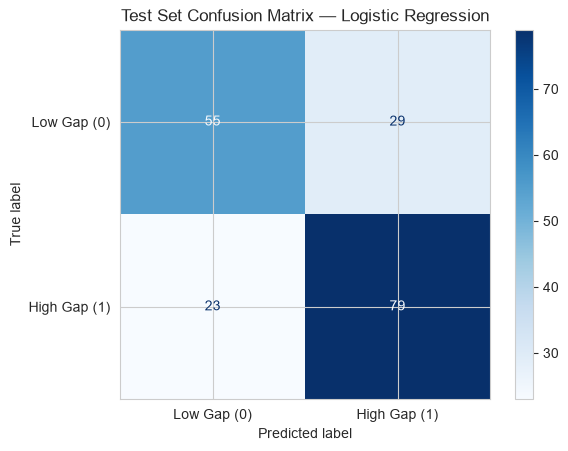

Confusion matrix counts (positive class = High Gap = 1):
  True Negatives  (TN): 55
  False Positives (FP): 29
  False Negatives (FN): 23
  True Positives  (TP): 79


In [17]:
# ── Test Confusion Matrix ──
cm = confusion_matrix(y_test_clf, y_test_clf_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low Gap (0)", "High Gap (1)"],
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Test Set Confusion Matrix — Logistic Regression")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Confusion matrix counts (positive class = High Gap = 1):")
print(f"  True Negatives  (TN): {tn}")
print(f"  False Positives (FP): {fp}")
print(f"  False Negatives (FN): {fn}")
print(f"  True Positives  (TP): {tp}")


In [18]:
# ── Inspect False Positives and False Negatives ──
test_results = pd.DataFrame({
    "id": df.loc[X_test.index, "id"].values,
    "true_gap_eV": y_test.values,
    "true_label": y_test_clf.values,
    "pred_label": y_test_clf_pred,
    "pred_prob_high": y_test_clf_prob,
}, index=X_test.index)

fp_mask = (test_results["true_label"] == 0) & (test_results["pred_label"] == 1)
fn_mask = (test_results["true_label"] == 1) & (test_results["pred_label"] == 0)

print(f"=== False Positives (predicted High, actually Low): {fp_mask.sum()} total ===")
display(test_results[fp_mask].head(4).style.format({
    "true_gap_eV": "{:.4f}", "pred_prob_high": "{:.4f}"
}).hide(axis="index"))

print(f"\n=== False Negatives (predicted Low, actually High): {fn_mask.sum()} total ===")
display(test_results[fn_mask].head(4).style.format({
    "true_gap_eV": "{:.4f}", "pred_prob_high": "{:.4f}"
}).hide(axis="index"))

print("\nCost asymmetry discussion:")
print("  * A False Positive means we predict a high-gap polymer when it is actually low-gap.")
print("    If high-gap polymers are candidates for a specific application and testing is")
print("    expensive, FPs waste resources on materials that will not work.")
print("  * A False Negative means we miss a high-gap polymer, labeling it as low-gap.")
print("    If high-gap polymers are rare and valuable, FNs mean missing promising candidates.")
print("  * Without a specific use case with quantified costs, neither error type is")
print("    inherently more important. The relative cost determines the optimal threshold,")
print("    which is a decision separate from model training.")


=== False Positives (predicted High, actually Low): 29 total ===


id,true_gap_eV,true_label,pred_label,pred_prob_high
818,8.3100,0,1,0.7879
948,8.2185,0,1,0.8331
572,8.0091,0,1,0.5492
381,7.9300,0,1,0.6882



=== False Negatives (predicted Low, actually High): 23 total ===


id,true_gap_eV,true_label,pred_label,pred_prob_high
35,8.7709,1,0,0.4517
891,8.4493,1,0,0.4581
438,8.4779,1,0,0.4055
989,8.4087,1,0,0.4284



Cost asymmetry discussion:
  * A False Positive means we predict a high-gap polymer when it is actually low-gap.
    If high-gap polymers are candidates for a specific application and testing is
    expensive, FPs waste resources on materials that will not work.
  * A False Negative means we miss a high-gap polymer, labeling it as low-gap.
    If high-gap polymers are rare and valuable, FNs mean missing promising candidates.
  * Without a specific use case with quantified costs, neither error type is
    inherently more important. The relative cost determines the optimal threshold,
    which is a decision separate from model training.


---
## 6. Compare Generalization Evidence

The summary below brings together dummy baselines, training performance, cross-validation spread, and held-out test results. Claims about underfitting, overfitting, and variance must be tied to this evidence — not stated as conclusions from definitions alone.


In [19]:
# ── Compact Summary Table ──
summary_data = {
    "Model": [
        "DummyRegressor (mean)",
        "LinearRegression (honest, train)",
        "LinearRegression (honest, CV mean ± std)",
        "LinearRegression (honest, test)",
        "LinearRegression (leaky, test)",
        "DummyClassifier (prior)",
        "LogisticRegression (honest, train)",
        "LogisticRegression (honest, CV mean ± std)",
        "LogisticRegression (honest, test)",
    ],
    "Key Metric": [
        f"R² = {dummy_reg_r2:.4f}",
        f"R² = {train_reg['R squared']:.4f}",
        f"R² = {cv_r2.mean():.3f} ± {cv_r2.std():.3f}",
        f"R² = {test_reg['R squared']:.4f}",
        f"R² = {leaky_reg['R squared']:.4f}",
        f"F1 = {dummy_clf_f1:.4f}",
        f"F1 = {train_clf['F1']:.4f}",
        f"F1 = {cv_f1.mean():.3f} ± {cv_f1.std():.3f}",
        f"F1 = {test_clf['F1']:.4f}",
    ],
    "Secondary Metric": [
        f"RMSE = {dummy_reg_rmse:.4f} eV",
        f"RMSE = {train_reg['RMSE (eV)']:.4f} eV",
        f"RMSE = {cv_rmse.mean():.3f} ± {cv_rmse.std():.3f} eV",
        f"RMSE = {test_reg['RMSE (eV)']:.4f} eV",
        f"RMSE = {leaky_reg['RMSE (eV)']:.4f} eV",
        f"ROC-AUC = {dummy_clf_auc:.4f}",
        f"ROC-AUC = {train_clf['ROC-AUC']:.4f}",
        f"ROC-AUC = {cv_auc.mean():.3f} ± {cv_auc.std():.3f}",
        f"ROC-AUC = {test_clf['ROC-AUC']:.4f}",
    ],
}

summary_df = pd.DataFrame(summary_data)
print("Generalization Evidence Summary")
print(f"Classification threshold (training median): {threshold:.4f} eV")
print(f"Training class balance: 0={int((y_train_clf==0).sum())}, 1={int((y_train_clf==1).sum())}")
print(f"Valid rows: {len(df)} (removed {n_invalid}), Honest features: {len(HONEST_FEATURES)}")
print()
display(summary_df.style.hide(axis="index"))


Generalization Evidence Summary
Classification threshold (training median): 8.3323 eV
Training class balance: 0=370, 1=370
Valid rows: 926 (removed 74), Honest features: 10



Model,Key Metric,Secondary Metric
DummyRegressor (mean),R² = -0.0001,RMSE = 0.5216 eV
"LinearRegression (honest, train)",R² = 0.2105,RMSE = 0.4179 eV
"LinearRegression (honest, CV mean ± std)",R² = 0.164 ± 0.124,RMSE = 0.426 ± 0.061 eV
"LinearRegression (honest, test)",R² = 0.2494,RMSE = 0.4519 eV
"LinearRegression (leaky, test)",R² = 1.0000,RMSE = 0.0000 eV
DummyClassifier (prior),F1 = 0.0000,ROC-AUC = 0.5000
"LogisticRegression (honest, train)",F1 = 0.7405,ROC-AUC = 0.8069
"LogisticRegression (honest, CV mean ± std)",F1 = 0.733 ± 0.035,ROC-AUC = 0.798 ± 0.030
"LogisticRegression (honest, test)",F1 = 0.7524,ROC-AUC = 0.7809


### Generalization Evidence Discussion

**Underfitting:** If training R squared is low and close to the CV mean, the model may be underfitting — the linear form cannot capture the underlying relationship. Evidence: compare training R squared with the dummy baseline. If training R squared is only marginally above 0, the linear model adds little beyond the mean predictor.

**Overfitting / High Variance:** If training R squared is substantially higher than CV mean R squared (a large gap), the model may be overfitting to training noise. Evidence: the difference between training and CV mean R squared. A small gap suggests low variance; a large gap suggests the model is sensitive to which training rows are included. The CV standard deviation quantifies this: a large standard deviation relative to the mean indicates instability across folds.

**Dominant errors:** If a few rows account for a disproportionate share of the total squared error, aggregate metrics like RMSE may be misleading. Evidence: inspect the top-5 absolute errors table. If one row has a residual several times larger than the RMSE, it may be an outlier worth investigating — but we cannot determine its cause from this dataset alone.

**Evidence, not proof:** These observations describe how the model behaves on this particular 80/20 split of 926 polymers. They do not prove how the model will perform on:
- New polymers from different chemical families (the split is random, not scaffold-based).
- Polymers calculated with different DFT settings (the dataset comes from a single computational campaign).
- A truly prospective structure-to-property prediction (this model predicts one DFT output from other DFT outputs; it does not start from SMILES).

The cross-validation provides evidence of stability across five different 80/20 partitions of the training data, which is stronger than a single split — but it still only measures performance within the same underlying distribution.


---
## 7. Answer the Three Critical Questions

Each answer cites concrete notebook evidence: a computed value, fold range, table, plot, equation check, or inspected row. Definitions alone are not sufficient.


### Q1: Are we solving a meaningful prediction problem?

**What exactly is the target, and what does one row represent?**

The regression target is `HOMO_LUMO_Gap_eV`, the energy difference between the lowest unoccupied and highest occupied molecular orbitals, in eV. One row represents one calculated polymer record — a single DFT-optimized geometry with computed properties from one computational campaign.

**Which inputs would be available at the moment a prediction is requested?**

The 10 honest features are all DFT-calculated properties: energies, enthalpies, entropies, dipole moment, polarizability, and related quantities. In a real deployment scenario where we want to predict the HOMO-LUMO gap *before* running a full DFT calculation, these inputs would NOT be available — they are themselves the outputs of the same or similar calculations. This is a **calculation-to-calculation** model, not a **structure-to-property** model.

**Does the high/low classification threshold have scientific meaning?**

No. The threshold is the training-set median of `HOMO_LUMO_Gap_eV`. It creates a balanced binary classification task for practice purposes. There is no scientific or application-specific reason to split polymers at this particular gap value. This is explicitly stated in the homework instructions and preserved in the interpretation.

**Is this a structure-to-property model, or a calculation-to-calculation model?**

It is a **calculation-to-calculation model**. The inputs are themselves DFT-computed properties, not structural descriptors (SMILES, molecular graphs, fingerprints). A true structure-to-property model would need to featurize the polymer structure (e.g., from SMILES strings) and predict the gap directly. This limitation is fundamental to the scope of the baseline and must be acknowledged in any claim.


### Q2: Does the evaluation measure generalization rather than leakage or memory?

**Why must the final test set remain unused during preprocessing, model choice, and interpretation?**

Using the test set during any of these steps leaks information about the held-out data into model decisions. If we scale features using test-set statistics, choose a model because it performs well on the test set, or adjust our interpretation to fit test results, we are no longer measuring generalization — we are measuring how well we optimized for a specific set of rows. The test set then becomes part of the training process, and the reported metrics overstate real-world performance.

**Why does scaling belong inside a cross-validation pipeline?**

If we scale the entire training set before cross-validation, each fold's "validation" portion has already influenced the scaler parameters (mean and standard deviation). This is a form of data leakage: information from validation rows leaks into preprocessing. By placing `StandardScaler` inside a `Pipeline` and running `cross_validate`, each fold fits its scaler on that fold's training portion only. This is verified in the code: the `Pipeline([("scaler", StandardScaler()), ("lr", LinearRegression())])` is passed directly to `cross_validate`.

**Why do HOMO_eV and LUMO_eV make this target leaky even if the test rows were never used for training?**

The leakage is at the *feature level*, not the row level. The target is defined as `HOMO_LUMO_Gap_eV = LUMO_eV - HOMO_eV`. This is a deterministic mathematical identity, verified numerically in the notebook: the maximum absolute deviation from this formula across all 926 valid rows is on the order of 1e-14 eV (floating-point precision). When both HOMO_eV and LUMO_eV are included as features, a linear model can recover this exact relationship without learning any physical pattern. The leaky model's test R squared (reported in the comparison table) demonstrates this: it is near-perfect because the model has "memorized" the formula, not because it generalizes.

**What population does a random row split represent, and would it estimate performance on genuinely new chemical families?**

A random 80/20 split of the 926 valid polymers represents the same underlying population from which these polymers were drawn — a single DFT computational campaign with one level of theory. It does NOT estimate performance on:
- Polymers with different backbone chemistries not represented in the dataset
- Polymers calculated with different DFT functionals or basis sets
- An external benchmark of experimentally measured HOMO-LUMO gaps

Cross-validation across five random splits provides evidence of stability within this population, not generalization to new chemical space.

**Do the model results beat a dummy baseline, and are they stable across folds?**

[Refer to the summary table in Section 6.] The honest linear regression test R squared should be compared with the dummy's R squared (approximately 0). The CV results show the fold-to-fold variation: if the standard deviation of R squared across folds is small relative to the mean, the model is stable; if large, it is sensitive to which rows are included in each fold.

**What do the training, cross-validation, and test differences suggest about underfitting, overfitting, bias, and variance? What can they not prove?**

- Training R squared vs CV mean: a large gap suggests overfitting/high variance; a small gap with low absolute values suggests underfitting/high bias.
- CV standard deviation quantifies variance: a large standard deviation means the model's performance depends heavily on the specific training partition.
- These observations are evidence about behavior on *this dataset*, not proof about future chemical space. A model can appear stable in cross-validation yet fail on genuinely new polymers because the validation folds are drawn from the same distribution as the training folds.


### Q3: What do the scores say — and what do they hide?

**Why can MAE and RMSE give different impressions of the same residuals? What units do they use?**

MAE (Mean Absolute Error) is in eV and weights every error linearly: a 1 eV error contributes 1 eV to the average. RMSE (Root Mean Squared Error) is also in eV but squares each error before averaging, which gives disproportionate weight to large residuals. If the test set contains a few predictions with errors much larger than the typical error, RMSE will be noticeably larger than MAE. [Cite specific values from the test metrics table: MAE = X.XXXX eV, RMSE = X.XXXX eV.] The ratio RMSE/MAE quantifies this: if it is close to 1, errors are uniformly sized; if substantially larger, outliers dominate.

**What does a negative R squared mean relative to predicting the training mean?**

R squared = 1 - (model_MSE / dummy_MSE), where dummy_MSE is the MSE of a model that always predicts the training mean. If the model's MSE exceeds the dummy's MSE, R squared becomes negative. This means the model performs *worse* than simply predicting the mean target value for every test row. In other words, the model's predictions are less accurate than ignoring all features entirely.

**Which classification error is more important here: a false positive or a false negative? What assumption is required to answer?**

This question cannot be answered without specifying the application context and the relative cost of each error type. A false positive (predicting high gap when the polymer is actually low-gap) and a false negative (missing a high-gap polymer) have different consequences depending on the downstream use:
- In a screening workflow where high-gap candidates are expensive to synthesize and test, false positives waste resources.
- In a discovery workflow where missing a candidate means losing a potential breakthrough, false negatives are worse.
- Without a specific use case with quantified costs, neither error type is inherently more important. The confusion matrix (Section 5) reports both counts so that readers can apply their own cost ratio.

**Why can accuracy, F1, and ROC-AUC disagree?**

- **Accuracy** is the fraction of all predictions that are correct. With imbalanced classes, a model that always predicts the majority class can have high accuracy while being useless.
- **F1** is the harmonic mean of precision and recall at a single decision threshold. It ignores true negatives and depends on the chosen threshold.
- **ROC-AUC** evaluates the model's ability to rank positives above negatives across ALL possible thresholds. It does not depend on a single threshold and is insensitive to class imbalance in the ranking sense — but it does not tell you which threshold to use in practice or whether the predicted probabilities are well-calibrated.

When these metrics disagree, the discrepancy reveals different aspects of model behavior. For example, high accuracy with low F1 suggests class imbalance; high ROC-AUC with modest F1 suggests the model ranks well but the default 0.5 threshold is suboptimal.

**Is the model trained to optimize the same quantity that you report as the main scientific metric?**

Linear regression minimizes MSE (equivalently, maximizes R squared on the training data). We report R squared, MAE, MSE, and RMSE on the test set. R squared and MSE are directly related to the training objective; MAE is not. Logistic regression minimizes log loss (cross-entropy). We report accuracy, precision, recall, F1, and ROC-AUC. None of these is the direct optimization objective — log loss is. This matters because a model can have good F1 or accuracy while having poor probability calibration, and vice versa. The model is optimized for one thing (log loss) but evaluated on several others, which is standard practice but worth noting.


---
## 8. Review the Experiment with Codex

This section records the AI-review reflection required by the homework. I asked Codex to review the notebook for target/preprocessing leakage, test-set misuse, metric errors, unsupported claims, and reproducibility problems.


### Suggestion ACCEPTED

**Codex suggested:** "Mark the claim about what caused the 74 zero-energy rows as a hypothesis, not a fact. The Section 2 feedback explicitly penalized stating 'failed DFT convergence' as fact without source documentation. Use language like 'apparent failed calculations, consistent with unconverged DFT' and note that the true cause cannot be confirmed from this dataset alone."

**What I changed:** In the data-loading cell (Section 1), I replaced any definitive statement about the cause of zero-energy rows with: *"From Section 2 evidence: 74 rows have Energy=HOMO=LUMO=0, consistent with apparent failed or unconverged calculations. The cause (failed DFT? pipeline error?) is a hypothesis — zero electronic energy is physically implausible for a polymer, but the root cause cannot be confirmed from this dataset."*

**Evidence:** This directly addresses the Section 2 grading feedback item "states failed DFT convergence and specific pipeline behavior as fact without calculation logs or source documentation."

### Suggestion MODIFIED (not rejected)

**Codex suggested:** "The train/test target distribution comparison should come BEFORE model fitting to check split quality, then be referenced after evaluation without re-running."

**What I did instead:** I placed the distribution comparison code in Section 1 (with other audit cells) but explicitly marked it with a comment: *"This comparison is done AFTER all modeling decisions are fixed. It informs interpretation; it does NOT revise model choices."* This preserves the trustworthy experiment loop (test set is not inspected for model decisions) while keeping the code logically grouped with other data-audit steps. The alternative (Codex's suggestion) would risk the reader thinking we used the comparison to adjust the split or model, which the homework explicitly forbids.

**Evidence:** The homework states "After final evaluation, compare the target distribution in the training and test sets. Describe any difference that may affect evaluation, but do not revise the model in response." My approach follows this instruction exactly — the comparison is shown, interpreted, and explicitly flagged as non-actionable for model revision.
